In [35]:
import zipfile
import os

# Unzip images directly into Colab's temporary storage for testing
print("Unzipping images for testing...")
if os.path.exists("/content/images-20260823T105631Z-1-001.zip"):
    with zipfile.ZipFile("/content/images-20260823T105631Z-1-001.zip", 'r') as zip_ref:
        zip_ref.extractall("/content/dataset/images")
print("done")

Unzipping images for testing...
done


In [36]:
import cv2
import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
import math
from google.colab import drive

!pip install segmentation-models-pytorch -q
import segmentation_models_pytorch as smp

# Mounting Drive to access saved models
drive.mount('/content/drive')
DRIVE_BASE = '/content/drive/MyDrive/Origin_Challenge_Submission'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#Define Model A
class LandmarkNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = models.resnet18(pretrained=False)
        self.model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.model.fc = nn.Linear(self.model.fc.in_features, 8)
    def forward(self, x): return self.model(x)

# Load Weights from Google Drive
model_A = LandmarkNet().to(device)
model_A.load_state_dict(torch.load(f'{DRIVE_BASE}/task_1_landmark/Model_Weights/hypothesis_final_saved_model.pth', map_location=device))
model_A.eval()

model_B = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=1, classes=1).to(device)
model_B.load_state_dict(torch.load(f'{DRIVE_BASE}/task_2_segmentation/Model_Weights/hypothesis_final_saved_model.pth', map_location=device))
model_B.eval()

print("Models loaded successfully from Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models loaded successfully from Google Drive!


Found image at: /content/dataset/images/images/000_HC.png


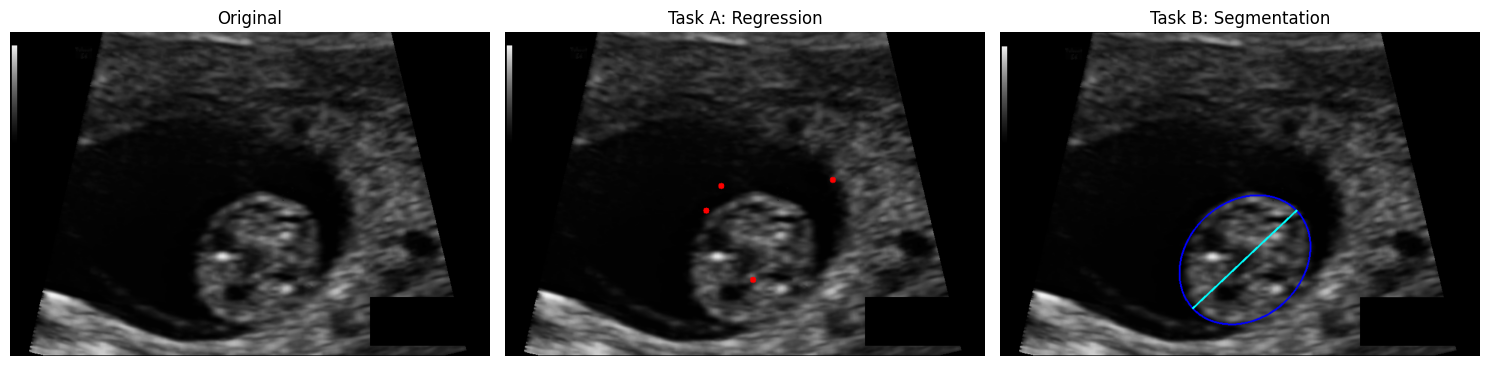

In [39]:
import os
import cv2
import torch
import math
import numpy as np
import matplotlib.pyplot as plt

def find_image_path(filename, search_dir='/content'):
    """Automatically searches all folders in Colab to find the image file."""
    for root, _, files in os.walk(search_dir):
        if filename in files:
            return os.path.join(root, filename)
    return None

def run_full_inference(image_filename='000_HC.png'):
    #Locate image automatically
    img_path = find_image_path(image_filename)
    if img_path is None:
        print(f"Error: '{image_filename}' not found anywhere in /content.")
        print("Please check the Colab file explorer on the left to verify the file or zip is uploaded.")
        return

    print(f"Found image at: {img_path}")
    orig_img = cv2.imread(img_path)
    orig_h, orig_w, _ = orig_img.shape
    gray = cv2.cvtColor(orig_img, cv2.COLOR_BGR2GRAY)
    input_img = cv2.resize(gray, (256, 256)) / 255.0
    input_tensor = torch.tensor(input_img, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

    # TASK A: LANDMARKS
    with torch.no_grad():
        preds_A = model_A(input_tensor).squeeze(0).cpu().numpy()

    scaled_preds = np.zeros_like(preds_A)
    scaled_preds[0::2] = preds_A[0::2] * (orig_w / 256.0)
    scaled_preds[1::2] = preds_A[1::2] * (orig_h / 256.0)

    vis_img_A = orig_img.copy()
    for i in range(0, 8, 2):
        pt = (int(scaled_preds[i]), int(scaled_preds[i+1]))
        cv2.circle(vis_img_A, pt, 5, (0, 0, 255), -1)

    # TASK B: SEGMENTATION
    with torch.no_grad():
        logits_B = model_B(input_tensor)
        pred_mask = torch.sigmoid(logits_B).squeeze().cpu().numpy()

    mask_uint8 = (pred_mask > 0.5).astype(np.uint8) * 255
    mask_orig = cv2.resize(mask_uint8, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
    contours, _ = cv2.findContours(mask_orig, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    vis_img_B = orig_img.copy()
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        if len(largest_contour) >= 5:
            ellipse = cv2.fitEllipse(largest_contour)
            cv2.ellipse(vis_img_B, ellipse, (255, 0, 0), 2)

            (xc, yc), (d1, d2), angle = ellipse
            major, minor = max(d1, d2), min(d1, d2)
            theta = math.radians(angle if d1 > d2 else angle + 90)

            ofd1 = (int(xc + (major/2) * math.cos(theta)), int(yc + (major/2) * math.sin(theta)))
            ofd2 = (int(xc - (major/2) * math.cos(theta)), int(yc - (major/2) * math.sin(theta)))
            cv2.line(vis_img_B, ofd1, ofd2, (255, 255, 0), 2)

    # plotting results
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    axs[0].imshow(cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB))
    axs[0].set_title("Original")
    axs[1].imshow(cv2.cvtColor(vis_img_A, cv2.COLOR_BGR2RGB))
    axs[1].set_title("Task A: Regression")
    axs[2].imshow(cv2.cvtColor(vis_img_B, cv2.COLOR_BGR2RGB))
    axs[2].set_title("Task B: Segmentation")
    for ax in axs: ax.axis('off')
    plt.tight_layout()
    plt.show()

#Run test by just passing the filename
run_full_inference('000_HC.png')